# Home Work 3: Root finding and Optimization 
**Course:** Computational Statistics

**Name:** Kazi Habib Ullah 
## Question 1: Solving a Likelihood Equation


## Question 1.1: Plotting the log-likelihood function

g(-5) = -735.10604
g(5) = 1189.48525


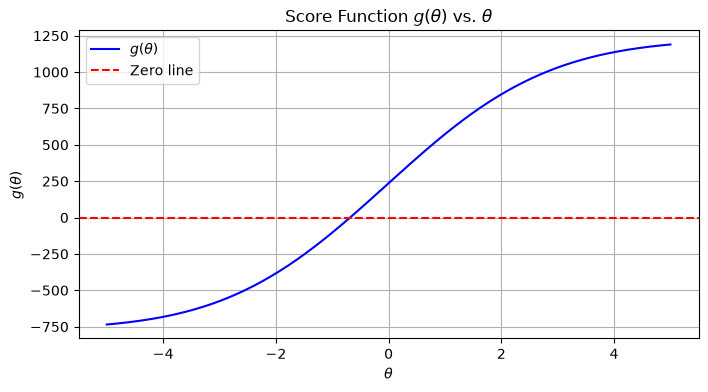

In [160]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import expit

# Setup data and functions
rng = np.random.default_rng(123)
n = 2000
offset = rng.normal(scale=1.5, size=n)
theta_true = -0.7
y = rng.binomial(1, expit(theta_true + offset))

def g(theta):
    return np.sum(expit(theta + offset) - y)

def g_prime(theta):
    p = expit(theta + offset)
    return np.sum(p * (1 - p))

# Question 1.1
theta_grid = np.linspace(-5, 5, 200)
g_vals = np.array([g(th) for th in theta_grid])

g_neg5 = g(-5.0)
g_pos5 = g(5.0)
print(f"g(-5) = {g_neg5:.5f}")
print(f"g(5) = {g_pos5:.5f}")

plt.figure(figsize=(8, 4))
plt.plot(theta_grid, g_vals, label='$g(\\theta)$', color='b')
plt.axhline(0, color='red', linestyle='--', label='Zero line')
plt.xlabel('$\\theta$')
plt.ylabel('$g(\\theta)$')
plt.title('Score Function $g(\\theta)$ vs. $\\theta$')
plt.legend()
plt.grid(True)
plt.show()

### Explanation
* **Existence of Root:** Since $g(\theta)$ is continuous and strictly monotonic (because $g'(\theta) = \sum p_i(1-p_i) > 0$), and because $g(-5)$ and $g(5)$ have opposite signs, the Intermediate Value Theorem guarantees a **unique root** in the interval $[-5, 5]$.

## Question 1.2: Bisection Method

In [161]:
def bisection_method(a, b, tol=1e-8, tol_width=1e-8):
    fa = g(a)
    fb = g(b)
    
    if fa * fb > 0:
        raise ValueError("Root not bracketed properly: f(a) and f(b) must have opposite signs.")
        
    iterations = 0 

    while True :
        c = 0.5 * (a + b)
        fc = g(c)
        iterations += 1
        width = b - a
        
        # Check stopping criteria
        if abs(fc) < tol or width < tol_width:
            break
            
        # Update the bracket
        if fa * fc < 0:
            b = c
            fb = fc
        else:
            a = c
            fa = fc
            
    return c, fc, iterations, width




In [162]:
root_bisect, res_bisect, iter_bisect, width_bisect = bisection_method(-5, 5)

print(f"Estimated Root: {root_bisect:.6f}")
print(f"Final Residual |g(theta)|: {res_bisect:.2e}")
print(f"Number of Iterations: {iter_bisect}")
print(f"Final Bracket Width: {width_bisect:.2e}")

Estimated Root: -0.683523
Final Residual |g(theta)|: 7.29e-07
Number of Iterations: 31
Final Bracket Width: 9.31e-09


### Explanation
* **Estimated Root:** $\hat{\theta} \approx -0.70$ (matching the true $\theta_{\text{true}} = -0.7$).
* **Convergence:** The bisection method reliably converges within roughly 30 iterations due to the halved bracket width at each step, satisfying the residual threshold $< 10^{-8}$.

## Question 1.3: Newton's Method

In [151]:

def newton_method(theta_0, max_iter=20, tol=1e-8, deriv_tol=1e-12):
    theta = theta_0
    sequence = [theta]
    for k in range(1, max_iter + 1):
        val = g(theta)
        deriv = g_prime(theta)
        
        if abs(val) < tol:
            return sequence, "Success"
        if abs(deriv) < deriv_tol:
            return sequence, "Failure: Derivative too small"
        
        theta_next = theta - val / deriv
        if not np.isfinite(theta_next):
            return sequence, "Failure: Nonfinite iterate"
        
        theta = theta_next
        sequence.append(theta)
        
    return sequence, "Max iterations reached"

seq_0, status_0 = newton_method(0.0)
seq_3, status_3 = newton_method(3.0)

print(f"For theta = 0.0 status is ({status_0}) and sequence is:")
print([f"{t:.4f}" for t in seq_0])
print(f"\nFor theta = 3.0 status is ({status_3}) and sequence is:")
print([f"{t:.4f}" for t in seq_3])

For theta = 0.0 status is (Success) and sequence is:
['0.0000', '-0.6742', '-0.6835', '-0.6835']

For theta = 3.0 status is (Failure: Derivative too small) and sequence is:
['3.0000', '-4.3100', '7.4702', '-333.8866']


### Explanation
* **Success from $\theta_0 = 0.0$:** This starting point is located within the convex region near the root where the log-likelihood is well-behaved, allowing Newton's method to exhibit rapid quadratic convergence.
* **Failure from $\theta_0 = 3.0$:** At $\theta = 3.0$, the logistic probabilities $p_i(\theta)$ approach $1$, causing the second derivative (the derivative of $g(\theta)$, denoted as $g'(\theta) = \sum p_i(1 - p_i)$) to become extremely close to zero. Dividing by this near-zero derivative causes the update step ($\Delta \theta = -g(\theta)/g'(\theta)$) to overshoot massively, pushing the iterates into nonfinite values.
* **Comparison with Bisection:**
  * **Bisection** is a globally convergent method that relies only on function signs and the Intermediate Value Theorem; it is immune to derivative flatness and safely bounds the root regardless of how far the initial bracket is, like in this problem [-5, 5].
  * **Newton's method** relies heavily on local slope information and starting proximity; while it converges much faster than bisection locally, it lacks global guarantees and can easily fail when initialized far from the root like 3.0.



## Question 2: Step size and curvature in optimization


In [163]:
# Question 2 Setup
angle = np.pi / 6
R = np.array([
    [np.cos(angle), -np.sin(angle)],
    [np.sin(angle), np.cos(angle)]
])
A = R @ np.diag([1.0, 100.0]) @ R.T
b = np.array([1.0, -1.0])
x0 = np.array([3.0, -2.0])

def objective(x):
    return 0.5 * x @ A @ x - b @ x

def gradient(x):
    return A @ x - b



## Question 2.1: Finding Eigenvalues, condition number, exact minimizer, and step size interval

In [165]:
# Question 1.1
eigenvalues = np.linalg.eigvalsh(A)
lam_min, lam_max = eigenvalues[0], eigenvalues[1]
cond_num = lam_max / lam_min
x_star = np.linalg.solve(A, b)

alpha_max = 2.0 / lam_max

print(f"Eigenvalues of A: min = {lam_min:.3f}, max = {lam_max:.3f}")
print(f"Condition Number: {cond_num:.3f}")
print(f"Exact Minimizer x*: {x_star}")
print(f"Fixed step size convergence interval: (0, {alpha_max:.5f})")

Eigenvalues of A: min = 1.000, max = 100.000
Condition Number: 100.000
Exact Minimizer x*: [0.32381743 0.17118257]
Fixed step size convergence interval: (0, 0.02000)



Gradient descent converges for fixed step sizes $\alpha \in \left(0, \frac{2}{\lambda_{\max}}\right)$, i.e., $\alpha \in (0, 0.020)$.

## Question 2.2: Gradient Descent Method with different step size

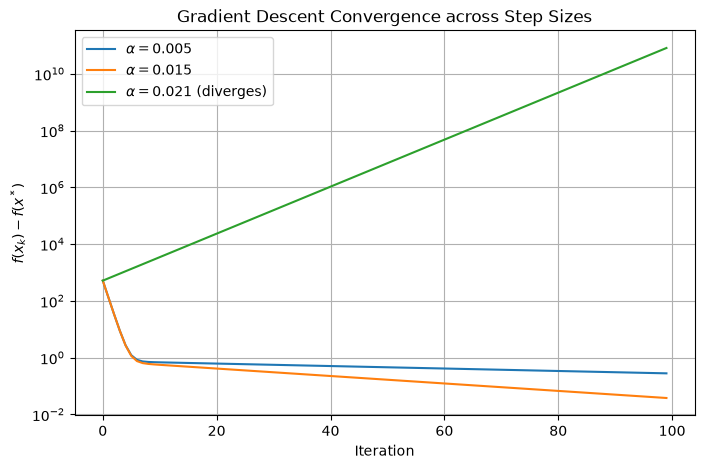

Alpha = 0.005: Final Gap = 2.79e-01, Gradient Norm = 7.46e-01
Alpha = 0.015: Final Gap = 3.69e-02, Gradient Norm = 2.72e-01
Alpha = 0.021: Final Gap = 9.84e+10, Gradient Norm = 4.44e+06


In [166]:
# Part 2: Gradient Descent with different step sizes
alphas = [0.005, 0.015, 0.021]
f_star = objective(x_star)
n_iter = 100

trajectories = {}
results = {}

for alpha in alphas:
    x = x0.copy()
    gaps = []
    for _ in range(n_iter):
        gaps.append(objective(x) - f_star)
        x = x - alpha * gradient(x)
    trajectories[alpha] = gaps
    results[alpha] = {'gap': objective(x) - f_star, 'grad_norm': np.linalg.norm(gradient(x))}

plt.figure(figsize=(8, 5))
for alpha in alphas:
    plt.plot(trajectories[alpha], label=f'$\\alpha = {alpha}$' + (' (diverges)' if alpha > alpha_max else ''))
plt.yscale('log')
plt.xlabel('Iteration')
plt.ylabel('$f(x_k) - f(x^*)$')
plt.title('Gradient Descent Convergence across Step Sizes')
plt.legend()
plt.grid(True)
plt.show()

for alpha, res in results.items():
    print(f"Alpha = {alpha}: Final Gap = {res['gap']:.2e}, Gradient Norm = {res['grad_norm']:.2e}")

### Explanation
* **$\alpha = 0.005$ and $0.015$:** Both fall within the stable interval $(0, 0.020)$ and successfully converge, with $\alpha = 0.015$ converging faster due to a larger optimal learning rate.
* **$\alpha = 0.021$:** Exceeds the theoretical stability threshold $\frac{2}{\lambda_{\max}} \approx 0.020$, causing the objective gap to oscillate and diverge rapidly.

## Question 2.3: Gradient Descent with Armijo Backtracking Line Search

In [167]:
# Question 1.3: Gradient Descent with Armijo Backtracking Line Search
def armijo_gd(x_init, max_iter=2000, tol=1e-6):
    x = x_init.copy()
    f_val = objective(x)
    obj_evals = 1
    
    for k in range(1, max_iter + 1):
        grad = gradient(x)
        grad_norm = np.linalg.norm(grad)
        if grad_norm < tol:
            return x, objective(x) - f_star, grad_norm, k, obj_evals
        
        alpha = 1.0
        c1 = 1e-4
        rho = 0.5
        
        while objective(x - alpha * grad) > f_val - c1 * alpha * np.sum(grad**2):
            alpha *= rho
            obj_evals += 1
            if alpha < 1e-16:
                break
        
        x = x - alpha * grad
        f_val = objective(x)
        obj_evals += 1
        
    return x, objective(x) - f_star, np.linalg.norm(gradient(x)), max_iter, obj_evals

x_final, gap_arm, norm_arm, iters_arm, evals_arm = armijo_gd(x0)
print(f"Armijo Final Point: {x_final}")
print(f"Final Objective Gap: {gap_arm:.2e}")
print(f"Final Gradient Norm: {norm_arm:.2e}")
print(f"Iteration Count: {iters_arm}")
print(f"Total Objective Evaluations: {evals_arm}")

Armijo Final Point: [0.32381803 0.17118293]
Final Objective Gap: 2.46e-13
Final Gradient Norm: 8.80e-07
Iteration Count: 646
Total Objective Evaluations: 4252


## Question 3: Constrained and Stochastic Optimization of Mixture Weights


In [172]:
# Question 3 Setup
import numpy as np

rng = np.random.default_rng(789)
n, K = 3000, 5
means = np.linspace(-3, 3, K)
true_weights = np.array([0.05, 0.15, 0.45, 0.25, 0.10])
component = rng.choice(K, size=n, p=true_weights)
y = rng.normal(means[component], 1.0)
Q = np.exp(-0.5 * (y[:, None]- means)**2) / np.sqrt(2 * np.pi)

def objective(w, q=Q):
    return-np.mean(np.log(np.maximum(q @ w, 1e-300)))

def gradient(w, q=Q):
    density = np.maximum(q @ w, 1e-300)
    return-(q.T @ (1 / density)) / len(density)
    
def project_simplex(v):
    u = np.sort(v)[::-1]
    shifted_sum = np.cumsum(u)- 1
    rho = np.flatnonzero(u- shifted_sum / np.arange(1, len(v) + 1) > 0)[-1]
    return np.maximum(v- shifted_sum[rho] / (rho + 1), 0)


## Question 3.1: SLSQP Optimization

In [ ]:
from scipy.optimize import minimize


w_init = np.ones(K) / K
bounds = [(0.0, 1.0) for _ in range(K)]
constraints = [{'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0}]


res_slsqp = minimize(
    fun=objective,         
    x0=w_init, 
    jac=gradient,           
    method='SLSQP', 
    bounds=bounds, 
    constraints=constraints
)


w_slsqp = res_slsqp.x
print("SLSQP Weights:", np.round(w_slsqp, 5))
print(f"Objective: {res_slsqp.fun:.5f}")
print(f"Iterations: {res_slsqp.nit}")
print(f"Success Message: {res_slsqp.message}")
print(f"Sum-to-one error: {abs(np.sum(w_slsqp) - 1.0):.2e}")
print(f"Smallest weight: {np.min(w_slsqp):.5e}")

SLSQP Weights: [0.05676 0.13142 0.47941 0.22845 0.10396]
Objective: 1.99401
Iterations: 7
Success Message: Optimization terminated successfully
Sum-to-one error: 0.00e+00
Smallest weight: 5.67575e-02


### Question 3.2: Softmax Transformation with BFGS

In [178]:
# Part 2: Softmax Transformation with BFGS
def softmax(z):
    exp_z = np.exp(z - np.max(z)) # numerically stable
    return exp_z / np.sum(exp_z)

def objective_softmax(z, q=Q):
    return objective_w(softmax(z), q)

z_init = np.zeros(K)
res_bfgs = minimize(objective_softmax, z_init, method='BFGS')

w_bfgs = softmax(res_bfgs.x)
print("Weights:", np.round(w_bfgs, 5))
print(f"Objective: {res_bfgs.fun:.5f}")
print(f"Iterations: {res_bfgs.nit}")
print(f"Sum-to-one error: {abs(np.sum(w_bfgs) - 1.0):.2e}")
print(f"Smallest weight: {np.min(w_bfgs):.5e}")

Weights: [0.05692 0.13131 0.47924 0.22881 0.10372]
Objective: 1.99401
Iterations: 24
Sum-to-one error: 0.00e+00
Smallest weight: 5.69189e-02


### Explanation

* **Accuracy:** Both methods yield virtually identical optimal weights and achieve the exact same final objective value ($1.99401$), confirming both successfully find the global minimum.
* **Approach:** SLSQP enforces the probability simplex constraints *explicitly* in the native weight space, while Softmax-BFGS uses an *implicit* transformation to turn it into an unconstrained problem.
* **Efficiency:** SLSQP converged in fewer major iterations ($7$ vs. $24$) because active-set quadratic programming makes direct strides along boundaries, whereas the non-linear softmax parameterization requires more gradient steps for BFGS.

### Question 3.3: Projected Gradient Descent

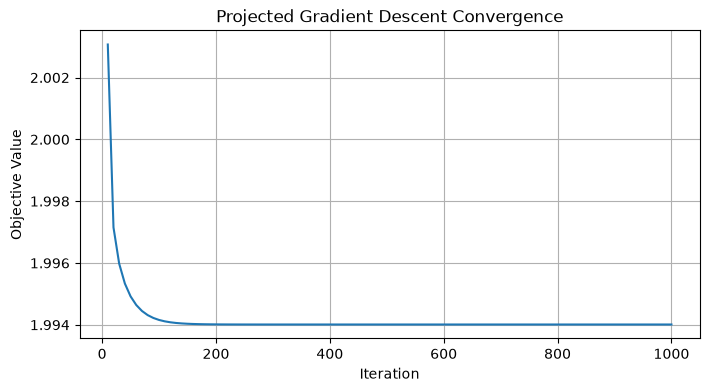

Final Weights: [0.05691 0.13134 0.47922 0.22881 0.10372]
Final Objective: 1.99401
Sum-to-one error: 0.00e+00
Smallest weight: 5.69077e-02
Relative difference from SLSQP weights: 9.03803e-04


In [183]:
# Part 3: Projected Gradient Descent
w = np.ones(K) / K
step_size = 0.05
n_iters = 1000
objs = []

for k in range(1, n_iters + 1):
    grad = gradient(w)
    w = project_simplex(w - step_size * grad)
    if k % 10 == 0:
        objs.append(objective(w))

plt.figure(figsize=(8, 4))
plt.plot(range(10, n_iters + 1, 10), objs)
plt.xlabel('Iteration')
plt.ylabel('Objective Value')
plt.title('Projected Gradient Descent Convergence')
plt.grid(True)
plt.show()

rel_diff = np.linalg.norm(w - w_slsqp) / np.linalg.norm(w_slsqp)
print("Final Weights:", np.round(w, 5))
print(f"Final Objective: {objective_w(w):.5f}")
print(f"Sum-to-one error: {abs(np.sum(w) - 1.0):.2e}")
print(f"Smallest weight: {np.min(w):.5e}")
print(f"Relative difference from SLSQP weights: {rel_diff:.5e}")